In [1]:
import os
import sys
sys.path.insert(0, "../src")

from processor import *
from reusables import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

In [2]:
DB_PATH = "Desktop/Data Analysis/incident_log.db"
START = '2026-10-12'

In [3]:
df, jobs, issues = prepare("../incident_log.db", start="2026-10-12")
weekly = weekly_summary(df, jobs)

In [4]:
#Setting variables for baseline and last week dataframes
baseline  = df[df['id'].between(3, 16)]
last_week = df.drop(baseline.index)
all_events = pd.concat([baseline, last_week])
all_jobs = 36 + 36

SUMMARY:

- There is significantly fewer losses and total cost from losses compared to the baseline week

- Searching for items accounts for a majority of the waste costs while also having fewer events than breakage across both reporting weeks.

- There is not enough data to draw any strong conclusions. 

WASTE:

In [5]:
#Total waste cost by type
cost_by(last_week)

,events,total
kind,,
Lost Item,2,388.8
Breakage,5,140.4
Repeat Trip,1,113.8


- This table represents the total events, separated by type, along with their costs. 

In [6]:
#Waste cost per 100 jobs by type
per_100_jobs(last_week, 36)

,events,total,events_per_100,cost_per_100
kind,,,,
Lost Item,2,388.8,5.6,1080.00
Breakage,5,140.4,13.9,390.00
Repeat Trip,1,113.8,2.8,316.11


- This table represents the total losses projected across 100 jobs.
- If this same loss rate continues across 100 jobs, these are the count of loss events and the cost after the 100th job.

CHARTS/GRAPHS

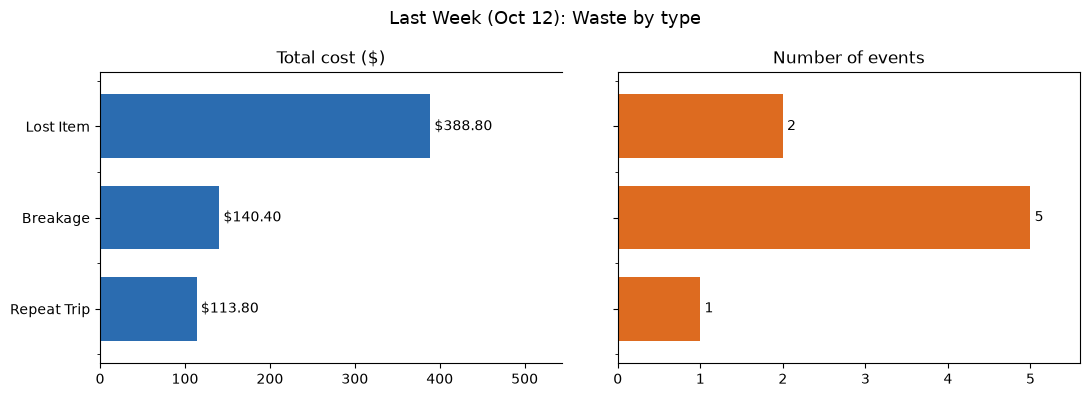

In [7]:
#Chart - Cost events chart (baseline and last week)
cost_events_chart(cost_by(last_week), 'Last Week (Oct 12): Waste by type')

- This graph compares the amount of waste is dollars to the number of events that took place during the week of October 12th.
- Lost items account for more than double the cost of breakage while also having fewer events in the week than breakage.

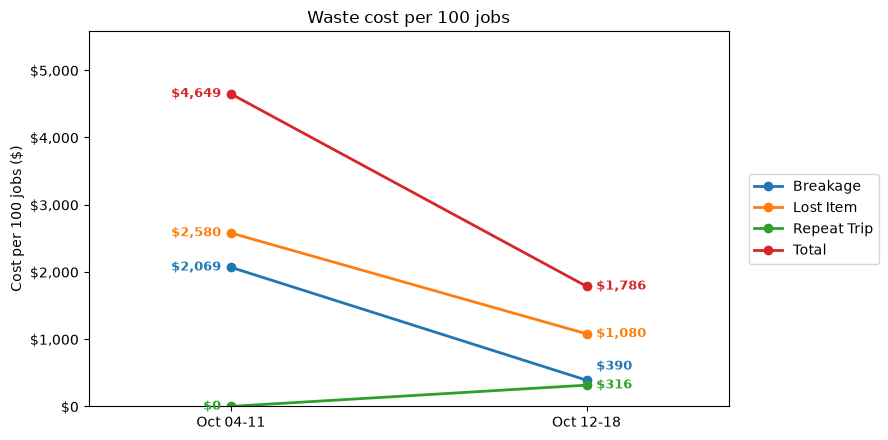

In [8]:
#Chart - Line chart of movementfrom baseline
weekly_cost_chart(
    {"Oct 04-11": baseline, "Oct 12-18": last_week},
    jobs={"Oct 04-11": 36, "Oct 12-18": 36}
)

- This graph shows the  projection of losses by type across 100 jobs and the change in cost from the baseline week to the current reporting week (Starting Oct 12).
- Last week there was less money wasted on loss events compared to the baseline week, however, there is not enough data yet to assume how significant this decrease is.

CONCLUSION:

- Far fewer loss events occured during the reporting week of October 12-18 than the events taken for the baseline week. While this change shows a decrease in waste, we cannot make any assumptions on if the decrease will hold steady, continue, or start increasing again. There will need to be another 3 weeks of data and reporting before averages can be made and we can start drawing accurate conclusions from the provided data. 